In [ ]:
import sys
from pathlib import Path
raiz_projeto = Path().resolve().parent
if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
sns.set_theme(style="whitegrid")


engine = create_engine(config.DATABASE_URL)

: 

In [ ]:
query = """
    SELECT c.customer_state,
       c.customer_city,
       COUNT(DISTINCT o.order_id) AS total_pedidos
FROM customers c
JOIN orders      o  ON o.customer_id = c.customer_id
JOIN order_items oi ON oi.order_id   = o.order_id
WHERE o.order_status <> 'canceled'
GROUP BY c.customer_state, c.customer_city
ORDER BY c.customer_state ASC, total_pedidos DESC;
"""

df = pd.read_sql(query, engine)
df.head(5)

,customer_state,customer_city,total_pedidos
0,AC,rio branco,70
1,AC,cruzeiro do sul,3
2,AC,senador guiomard,2
3,AC,xapuri,2
4,AC,manoel urbano,1


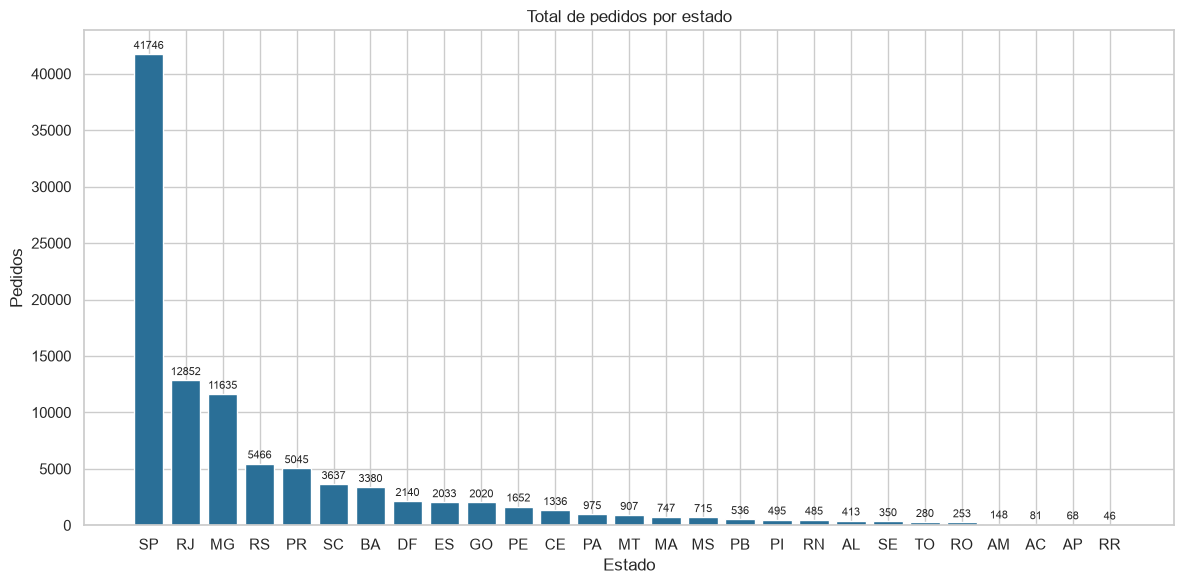

In [3]:
por_estado = (
    df.groupby("customer_state")["total_pedidos"]
      .sum()
      .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(por_estado.index, por_estado.values, color="#2a6f97")
ax.set_title("Total de pedidos por estado")
ax.set_xlabel("Estado")
ax.set_ylabel("Pedidos")
ax.bar_label(ax.containers[0], fontsize=8, padding=2)
plt.tight_layout()
plt.show()

In [4]:
idx_max = df.groupby("customer_state")["total_pedidos"].idxmax()
idx_min = df.groupby("customer_state")["total_pedidos"].idxmin()

top_cidades = df.loc[idx_max].set_index("customer_state")
bottom_cidades = df.loc[idx_min].set_index("customer_state")

# tabela comparativa
resumo = top_cidades[["customer_city", "total_pedidos"]].join(
    bottom_cidades[["customer_city", "total_pedidos"]],
    lsuffix="_max", rsuffix="_min"
)
print(resumo)

               customer_city_max  total_pedidos_max      customer_city_min  \
customer_state                                                               
AC                    rio branco                 70          manoel urbano   
AL                        maceio                247                atalaia   
AM                        manaus                140            itacoatiara   
AP                        macapa                 54        vitoria do jari   
BA                      salvador               1245       itaju do colonia   
CE                     fortaleza                654      antonina do norte   
DF                      brasilia               2131              ceilandia   
ES                       vitoria                379               mucurici   
GO                       goiania                692             aragoiania   
MA                      sao luis                353                 moncao   
MG                belo horizonte               2773             

C:\Users\vitor\AppData\Local\Temp\ipykernel_12916\2891029547.py:8: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  resumo = top_cidades[["customer_city", "total_pedidos"]].join(


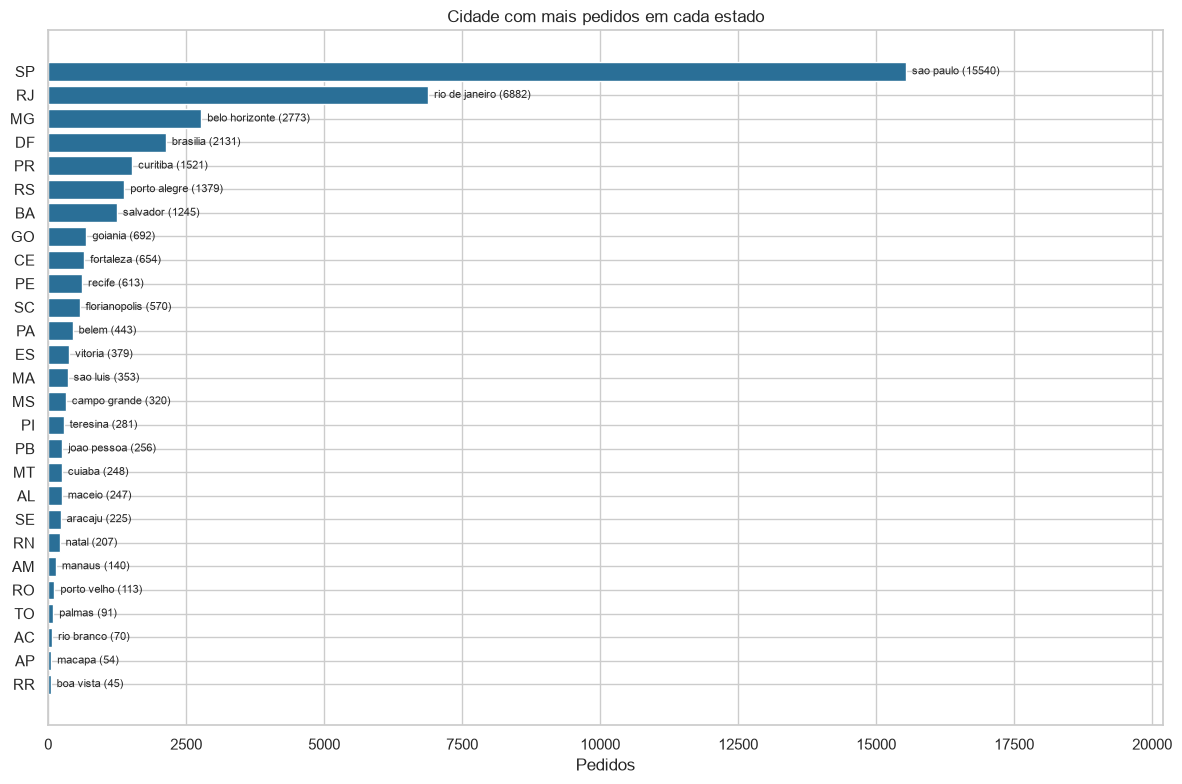

In [5]:
top = top_cidades.sort_values("total_pedidos", ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(top.index, top["total_pedidos"], color="#2a6f97")
ax.invert_yaxis()
ax.set_title("Cidade com mais pedidos em cada estado")
ax.set_xlabel("Pedidos")

for i, (estado, row) in enumerate(top.iterrows()):
    ax.text(row["total_pedidos"], i, f"  {row['customer_city']} ({row['total_pedidos']})",
            va="center", fontsize=8)

ax.set_xlim(0, top["total_pedidos"].max() * 1.3)
plt.tight_layout()
plt.show()